# 01 · Serie de demanda

**Objetivo:** construir la serie histórica mensual de demanda de autos, por línea. Es el paso 1 del TP y la entrada del pronóstico.

**Entrada:** `data/sales_data_sample_raw.csv`  
**Salida:** `outputs/serie_mensual.csv` y `outputs/serie_mensual.png`, que después lee `02_pronostico.ipynb`.

Antes de usar cualquier número en el informe: *Restart* y *Run All*.

**Cómo leer las referencias:** "consigna, sección 2" es la consigna del TP. En el apunte *Introducción a los Modelos de Inventarios*, el número es el que aparece al pie de la diapositiva (por ejemplo, 65/73), no la página del visor de PDF. En la presentación *Modelos de Pronósticos*, es el número de diapositiva.

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

RUTA_DATOS = "data/sales_data_sample_raw.csv"
CARPETA_SALIDA = "outputs"
os.makedirs(CARPETA_SALIDA, exist_ok=True)

## 1. Carga del dataset

El archivo viene codificado en latin-1, no en UTF-8. Columnas que se usan:

| Columna | Qué es |
|---|---|
| `ORDERNUMBER` | Número de la orden de compra |
| `ORDERLINENUMBER` | Número de fila dentro de esa orden |
| `ORDERDATE` | Fecha del pedido |
| `STATUS` | Estado del pedido (despachado, cancelado, en proceso, etc.) |
| `PRODUCTLINE` | Línea de producto |
| `PRODUCTCODE` | Modelo de auto |
| `QUANTITYORDERED` | Unidades pedidas de ese modelo |

In [2]:
df = pd.read_csv(RUTA_DATOS, encoding="latin-1")
df["ORDERDATE"] = pd.to_datetime(df["ORDERDATE"], format="%m/%d/%Y %H:%M")

print("Filas:", len(df))
print("Desde", df["ORDERDATE"].min().date(), "hasta", df["ORDERDATE"].max().date())

Filas: 2823
Desde 2003-01-06 hasta 2005-05-31


### Una orden, varias filas

Una orden es una compra de un cliente en una fecha, y puede incluir varios modelos de auto. El dataset guarda **una fila por cada modelo dentro de la orden**: a cada una de esas filas se la llama *línea de pedido*. `ORDERLINENUMBER` las numera (1, 2, 3...) y `QUANTITYORDERED` dice cuántos autos de ese modelo se pidieron.

Ejemplo: la orden 10100 tiene 4 filas, una por cada modelo Vintage que se pidió. Es una sola orden, con 4 filas y 151 autos.

In [3]:
orden = df[df["ORDERNUMBER"] == 10100]
orden = orden[["ORDERNUMBER", "ORDERLINENUMBER", "ORDERDATE", "PRODUCTLINE", "PRODUCTCODE", "QUANTITYORDERED"]]
orden = orden.sort_values("ORDERLINENUMBER").reset_index(drop=True)

print("Filas de la orden 10100:", len(orden))
print("Autos de la orden 10100:", orden["QUANTITYORDERED"].sum())
orden

Filas de la orden 10100: 4
Autos de la orden 10100: 151


,ORDERNUMBER,ORDERLINENUMBER,ORDERDATE,PRODUCTLINE,PRODUCTCODE,QUANTITYORDERED
0,10100,1,2003-01-06,Vintage Cars,S24_3969,49
1,10100,2,2003-01-06,Vintage Cars,S18_2248,50
2,10100,3,2003-01-06,Vintage Cars,S18_1749,30
3,10100,4,2003-01-06,Vintage Cars,S18_4409,22


### Chequeo de anomalías

En la clase del 24/9/2025, el profesor pidió revisar el dataset antes de usarlo: cantidades negativas o en cero, precios absurdos, filas duplicadas y estados raros. Las dos celdas de abajo lo revisan sobre el dataset completo.

In [4]:
print("Cantidades menores o iguales a 0:", (df["QUANTITYORDERED"] <= 0).sum())
print("Cantidad mínima y máxima por fila:", df["QUANTITYORDERED"].min(), "y", df["QUANTITYORDERED"].max())
print("Filas duplicadas completas:", df.duplicated().sum())
print("Filas con la misma orden y el mismo número de línea:", df.duplicated(["ORDERNUMBER", "ORDERLINENUMBER"]).sum())
print("\nEstados que aparecen:")
print(df["STATUS"].value_counts())

Cantidades menores o iguales a 0: 0
Cantidad mínima y máxima por fila: 6 y 97
Filas duplicadas completas: 0
Filas con la misma orden y el mismo número de línea: 0

Estados que aparecen:
STATUS
Shipped       2617
Cancelled       60
Resolved        47
On Hold         44
In Process      41
Disputed        14
Name: count, dtype: int64


In [5]:
precio_unitario = df["SALES"] / df["QUANTITYORDERED"]
print("Filas con PRICEEACH o SALES menores o iguales a 0:", ((df["PRICEEACH"] <= 0) | (df["SALES"] <= 0)).sum())

no_cierra = (df["SALES"] - df["QUANTITYORDERED"] * df["PRICEEACH"]).abs() > 0.01
print("Filas donde SALES no es QUANTITYORDERED × PRICEEACH:", no_cierra.sum())
print("De esas, con PRICEEACH exactamente en 100:", (no_cierra & (df["PRICEEACH"] == 100)).sum())
print("Valor máximo de PRICEEACH:", df["PRICEEACH"].max())

print("\nSALES / QUANTITYORDERED: mínimo", round(precio_unitario.min(), 2), "y máximo", round(precio_unitario.max(), 2))
por_modelo = precio_unitario.groupby(df["PRODUCTCODE"]).agg(["min", "max"])
print("Mayor diferencia de precio dentro de un mismo modelo:", round((por_modelo["max"] / por_modelo["min"]).max(), 1), "veces")

Filas con PRICEEACH o SALES menores o iguales a 0: 0
Filas donde SALES no es QUANTITYORDERED × PRICEEACH: 1304
De esas, con PRICEEACH exactamente en 100: 1304
Valor máximo de PRICEEACH: 100.0

SALES / QUANTITYORDERED: mínimo 26.88 y máximo 252.87
Mayor diferencia de precio dentro de un mismo modelo: 9.4 veces


**Resultado:**

- **Cantidades, duplicados y estados:** no hay cantidades negativas ni en cero (van de 6 a 97 por fila), no hay filas duplicadas, y los seis estados son los esperables, sin valores mal escritos.
- **Precios:** `PRICEEACH` tiene un tope en 100. Las 1.304 filas donde `SALES` no coincide con cantidad × precio tienen `PRICEEACH` exactamente en 100, que es su valor máximo: el precio real era mayor y quedó cortado. Por eso el precio se calcula como `SALES / QUANTITYORDERED`, como confirmó la cátedra. Además, el precio unitario de un mismo modelo varía mucho entre pedidos: hasta unas 9 veces entre su venta más barata y la más cara.

Nada de esto afecta la serie de demanda, que usa solo cantidades. Los precios importan más adelante, cuando se calcule el precio de los autos.

## 2. Líneas de producto

El caso de Heritage Motors tiene dos líneas: **Autos Clásicos** y **Autos Vintage** (consigna, "Contexto del Caso"). El dataset trae siete líneas de producto; se conservan solo `Classic Cars` y `Vintage Cars`.

In [6]:
print(df["PRODUCTLINE"].value_counts())

autos = df[df["PRODUCTLINE"].isin(["Classic Cars", "Vintage Cars"])].copy()
autos["mes"] = autos["ORDERDATE"].dt.to_period("M")
print("\nFilas de Classic Cars y Vintage Cars:", len(autos))

PRODUCTLINE
Classic Cars        967
Vintage Cars        607
Motorcycles         331
Planes              306
Trucks and Buses    301
Ships               234
Trains               77
Name: count, dtype: int64

Filas de Classic Cars y Vintage Cars: 1574


## 3. Estado del pedido

**Decisión:** se excluyen solo los pedidos cancelados (`Cancelled`).

**Respaldo de la cátedra:** en la clase del 24/9/2025, el profesor dijo que los pedidos en proceso en principio no los eliminaría, y que los cancelados tal vez sí. Para los demás estados (retenidos, en disputa y resueltos) el criterio es propio y sigue la misma lógica.

**Por qué:** la demanda es lo que los clientes pidieron, se haya despachado o no. Un pedido cancelado no consumió componentes. Uno en proceso, retenido o en disputa sí es demanda: el cliente lo pidió.

La alternativa sería quedarse solo con los despachados (`Shipped`). Se descarta porque los pedidos que todavía no se despacharon se concentran al final del dataset, y con ese filtro la demanda de los últimos meses quedaría subestimada. La tabla muestra entre qué fechas aparece cada estado: los `In Process`, por ejemplo, son todos de los últimos tres días de mayo de 2005.

In [7]:
autos.groupby("STATUS")["ORDERDATE"].agg(filas="count", primera="min", ultima="max")

,filas,primera,ultima
STATUS,,,
Cancelled,29,2003-10-23,2004-06-24
Disputed,5,2005-04-15,2005-05-09
In Process,30,2005-05-29,2005-05-31
On Hold,21,2004-11-19,2005-05-06
Resolved,18,2003-10-21,2005-03-01
Shipped,1471,2003-01-06,2005-05-17


### Comparación de los dos filtros

La tabla calcula la demanda mensual de dos formas, para los últimos 6 meses:

- **solo Shipped:** cuenta solo los pedidos que ya se habían despachado.
- **sin Cancelled:** cuenta todos los pedidos menos los cancelados.
- **diferencia:** autos que se pidieron en ese mes pero no se habían despachado cuando termina el dataset (31/05/2005).

En diciembre de 2004 la diferencia es 0: todo lo pedido ese mes ya se había despachado. En mayo de 2005, en cambio, el filtro "solo Shipped" pierde la mayor parte de la demanda Vintage del mes, como si nadie la hubiera pedido.

In [8]:
solo_shipped = autos[autos["STATUS"] == "Shipped"].pivot_table(
    index="mes", columns="PRODUCTLINE", values="QUANTITYORDERED", aggfunc="sum", fill_value=0)
sin_cancelled = autos[autos["STATUS"] != "Cancelled"].pivot_table(
    index="mes", columns="PRODUCTLINE", values="QUANTITYORDERED", aggfunc="sum", fill_value=0)

comparacion = pd.DataFrame({
    "Clasicos: solo Shipped": solo_shipped["Classic Cars"],
    "Clasicos: sin Cancelled": sin_cancelled["Classic Cars"],
    "Clasicos: diferencia": sin_cancelled["Classic Cars"] - solo_shipped["Classic Cars"],
    "Vintage: solo Shipped": solo_shipped["Vintage Cars"],
    "Vintage: sin Cancelled": sin_cancelled["Vintage Cars"],
    "Vintage: diferencia": sin_cancelled["Vintage Cars"] - solo_shipped["Vintage Cars"],
})
comparacion.tail(6)

,Clasicos: solo Shipped,Clasicos: sin Cancelled,Clasicos: diferencia,Vintage: solo Shipped,Vintage: sin Cancelled,Vintage: diferencia
mes,,,,,,
2004-12,1006,1006,0,818,818,0
2005-01,1099,1333,234,539,774,235
2005-02,1352,1352,0,776,776,0
2005-03,882,882,0,679,736,57
2005-04,400,1021,621,220,462,242
2005-05,930,1513,583,98,867,769


### Por qué importa justo al final de la serie

El suavizado exponencial pronostica así (presentación *Modelos de Pronósticos*, diapositiva 27):

$$F_t = F_{t-1} + \alpha \, (D_{t-1} - F_{t-1})$$

Cada pronóstico es el anterior corregido por una fracción α del último error. Si el último dato real está mal, ese error entra directo en el pronóstico siguiente. La celda de abajo calcula cuánto cambiaría el pronóstico de junio de 2005 de Vintage, con α = 0,3, solo por usar el dato de mayo de un filtro o del otro.

Si se desarrolla la fórmula hacia atrás, el último mes pesa α, el anterior α(1−α), el anterior α(1−α)², y así: cada mes más viejo pesa menos. Esta expansión es una cuenta propia a partir de la fórmula; no está escrita así en la presentación. La presentación sí señala lo contrario para la regresión lineal, que le da igual peso a todos los datos (diapositiva 48).

Winters actualiza el nivel con la misma estructura (diapositiva 54). Además, una caída artificial al final la interpretaría como una tendencia hacia abajo.

In [9]:
alfa = 0.3

mayo_shipped = solo_shipped.loc["2005-05", "Vintage Cars"]
mayo_sin_cancelled = sin_cancelled.loc["2005-05", "Vintage Cars"]
print("Vintage, mayo 2005: solo Shipped =", mayo_shipped, "| sin Cancelled =", mayo_sin_cancelled)
print("Cambio en el pronóstico de junio por ese solo dato:", round(alfa * (mayo_sin_cancelled - mayo_shipped)), "autos")

print("\nPeso de cada mes en el pronóstico, con alfa =", alfa)
for k in range(6):
    print("  hace", k + 1, "mes(es):", round(alfa * (1 - alfa) ** k, 3))

Vintage, mayo 2005: solo Shipped = 98 | sin Cancelled = 867
Cambio en el pronóstico de junio por ese solo dato: 231 autos

Peso de cada mes en el pronóstico, con alfa = 0.3
  hace 1 mes(es): 0.3
  hace 2 mes(es): 0.21
  hace 3 mes(es): 0.147
  hace 4 mes(es): 0.103
  hace 5 mes(es): 0.072
  hace 6 mes(es): 0.05


In [10]:
autos = autos[autos["STATUS"] != "Cancelled"]
print("Filas sin cancelados:", len(autos))

Filas sin cancelados: 1545


## 4. Unidad de demanda

**Decisión (confirmada por la cátedra por consulta):** un auto es una unidad de `QUANTITYORDERED`, no una fila.

Como se vio en la sección 1, cada fila es una línea de pedido, y cada línea trae en promedio unos 35 autos. Si se contaran filas, la orden 10100 valdría 4 autos en lugar de 151.

La tabla muestra las dos formas de contar para todo el período. No se usa más adelante: está para dejar a la vista el error que se evita. Contar filas daría unas 35 veces menos demanda de la real.

In [11]:
conteos = pd.DataFrame({
    "filas (lineas de pedido)": autos.groupby("PRODUCTLINE").size(),
    "autos (suma de QUANTITYORDERED)": autos.groupby("PRODUCTLINE")["QUANTITYORDERED"].sum(),
})
conteos["autos por fila (promedio)"] = (conteos["autos (suma de QUANTITYORDERED)"] / conteos["filas (lineas de pedido)"]).round(1)
conteos

,filas (lineas de pedido),autos (suma de QUANTITYORDERED),autos por fila (promedio)
PRODUCTLINE,,,
Classic Cars,951,33499,35.2
Vintage Cars,594,20609,34.7


## 5. Período: mensual

**Decisión:** serie mensual.

**Por qué:**

1. **Hace falta un dato en cada período.** En la clase del 8/10/2025, el profesor explicó que los modelos de pronóstico suponen un dato por período: si hay períodos sin demanda, hace falta un modelo de demanda intermitente. Por eso pidió agregar la serie (semanal, quincenal o mensual) hasta que todos los períodos tengan datos. La tabla de abajo cuenta los períodos sin demanda con cada agregación: la semanal y la quincenal tienen, y la mensual es la primera que no tiene ninguno.
2. **No alcanza para estimar la estacionalidad semanal.** Con 2 años y 5 meses, cada semana del año se observa solo 2 o 3 veces. Winters tendría que estimar 52 factores estacionales a partir de datos muy ruidosos (20 semanas tienen demanda total cero). Con la serie mensual son 12 factores, y cada uno sale de datos más estables. *Criterio propio.*
3. **Es como trabaja el apunte de la cátedra.** En el ejemplo de Electro, la demanda es mensual y el lead time se pasa a meses: E[x] = LT · E[d] y σx = σd · √LT (apunte de inventarios, diapositiva 65/73), con 1 semana = 0,25 mes (diapositiva 66/73).

La consigna habla de la desviación del error "a nivel de período (ej. semanal)" (consigna, sección 2): la semana es un ejemplo, no una obligación.

In [12]:
frecuencias = {"semanal": "W", "quincenal": "SMS", "mensual": "MS"}

filas = []
for nombre, codigo in frecuencias.items():
    agregada = autos.set_index("ORDERDATE").groupby("PRODUCTLINE")["QUANTITYORDERED"].resample(codigo).sum().unstack(0).fillna(0)
    agregada["Total"] = agregada["Classic Cars"] + agregada["Vintage Cars"]
    filas.append({
        "frecuencia": nombre,
        "periodos": len(agregada),
        "Clasicos sin demanda": int((agregada["Classic Cars"] == 0).sum()),
        "Vintage sin demanda": int((agregada["Vintage Cars"] == 0).sum()),
        "Total sin demanda": int((agregada["Total"] == 0).sum()),
    })

pd.DataFrame(filas).set_index("frecuencia")

,periodos,Clasicos sin demanda,Vintage sin demanda,Total sin demanda
frecuencia,,,,
semanal,126,39,43,20
quincenal,58,7,10,2
mensual,29,0,0,0


## 6. Serie mensual

Se suman las unidades por mes y por línea, y se agrega la columna `Total`.

Una serie de tiempo necesita datos equiespaciados, es decir, un dato por cada período sin saltos (presentación *Modelos de Pronósticos*, diapositiva 5). Por eso se reindexa con todos los meses del rango: si faltara alguno, aparece con 0 en lugar de desaparecer.

In [13]:
serie = autos.pivot_table(index="mes", columns="PRODUCTLINE",
                          values="QUANTITYORDERED", aggfunc="sum", fill_value=0)

todos_los_meses = pd.period_range(serie.index.min(), serie.index.max(), freq="M")
serie = serie.reindex(todos_los_meses, fill_value=0)

serie = serie.rename(columns={"Classic Cars": "Clasicos", "Vintage Cars": "Vintage"})
serie.columns.name = None
serie["Total"] = serie["Clasicos"] + serie["Vintage"]
serie

,Clasicos,Vintage,Total
2003-01,334,572,906
2003-02,120,301,421
2003-03,929,563,1492
2003-04,465,244,709
2003-05,934,584,1518
2003-06,338,313,651
2003-07,765,295,1060
2003-08,339,264,603
2003-09,1139,587,1726
2003-10,1988,1000,2988


### Verificación

Tiene que dar 29 meses, y en la tabla de totales: Clasicos 33499, Vintage 20609 y Total 54108.

In [14]:
print("Meses:", len(serie))
serie.sum().to_frame("autos en todo el periodo")

Meses: 29


,autos en todo el periodo
Clasicos,33499
Vintage,20609
Total,54108


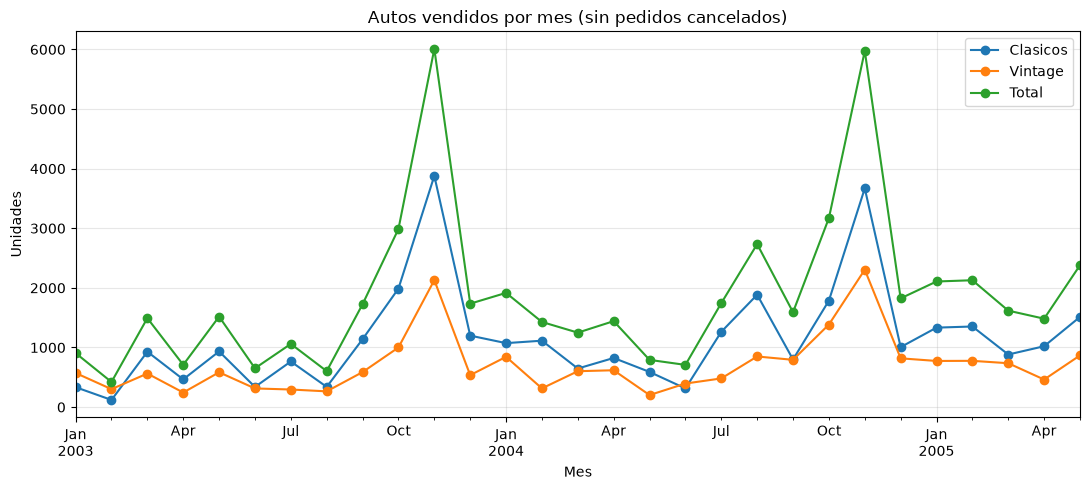

In [15]:
ax = serie.plot(marker="o", figsize=(11, 5))
ax.set_title("Autos vendidos por mes (sin pedidos cancelados)")
ax.set_xlabel("Mes")
ax.set_ylabel("Unidades")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(CARPETA_SALIDA, "serie_mensual.png"), dpi=150)
plt.show()

## 7. Lectura de la serie

Tres cosas para mirar, porque orientan el pronóstico:

1. **Estacionalidad:** ¿se repite algún pico en el mismo mes de cada año?
2. **Tendencia:** ¿la demanda crece, baja o se mantiene de un año al otro?
3. **Reparto entre líneas:** ¿la proporción de Clásicos sobre el total es estable? Esto importa para decidir si se pronostica el total o cada línea.

In [16]:
anual = serie.groupby(serie.index.year).sum()
anual["% Clasicos"] = (anual["Clasicos"] / anual["Total"] * 100).round(1)
print("Totales por año calendario (2005 tiene solo enero a mayo):")
print(anual)

ene_may_2004 = serie.loc["2004-01":"2004-05", "Total"].sum()
ene_may_2005 = serie.loc["2005-01":"2005-05", "Total"].sum()
print("\nEnero-mayo 2005 contra enero-mayo 2004:", round((ene_may_2005 / ene_may_2004 - 1) * 100, 1), "%")

proporcion_mensual = serie["Clasicos"] / serie["Total"] * 100
print("Proporción mensual de Clásicos: mínimo", round(proporcion_mensual.min(), 1),
      "%, máximo", round(proporcion_mensual.max(), 1), "%")

Totales por año calendario (2005 tiene solo enero a mayo):
      Clasicos  Vintage  Total  % Clasicos
2003     12429     7389  19818        62.7
2004     14969     9605  24574        60.9
2005      6101     3615   9716        62.8

Enero-mayo 2005 contra enero-mayo 2004: 42.3 %
Proporción mensual de Clásicos: mínimo 28.5 %, máximo 78.0 %


**Lo que muestra la serie:**

- **Estacionalidad:** noviembre es el pico los dos años, con unos 6.000 autos, y octubre también sube. El patrón se repite cada 12 meses.
- **Tendencia creciente:** 2004 vendió un 24% más que 2003, y enero-mayo de 2005 un 42% más que el mismo período de 2004.
- **Reparto entre líneas:** año a año los Clásicos son un 61-63% del total, pero mes a mes la proporción va del 29% al 78%.

Tendencia más estacionalidad es el caso para el que está pensado el método de Winters (presentación *Modelos de Pronósticos*, diapositiva 52). En `02_pronostico.ipynb` se compara contra los otros modelos de la unidad antes de elegirlo.

In [17]:
serie.to_csv(os.path.join(CARPETA_SALIDA, "serie_mensual.csv"), index_label="mes")
print("Guardado en", CARPETA_SALIDA)

Guardado en outputs
